In [1]:
include("GodunovMethod.jl")


MovingGridsDynamicStep (generic function with 1 method)

In [2]:
using DataFrames
using PrettyTables

γ = BigFloat("1.4")
ε = BigFloat("1e-15")

Tests = DataFrame(
    Test = Int8[],
    ρₗ = BigFloat[],
    uₗ = BigFloat[],
    pₗ = BigFloat[],
    ρᵣ = BigFloat[],
    uᵣ = BigFloat[],
    pᵣ = BigFloat[],
    t = BigFloat[]
)

push!(Tests, [1 BigFloat("1.0") BigFloat("0.0") BigFloat("1.0") BigFloat("0.125") BigFloat("0.0") BigFloat("0.1") BigFloat("0.25")])
push!(Tests, [2 BigFloat("1.0") BigFloat("-2.0") BigFloat("0.4") BigFloat("1.0") BigFloat("2.0") BigFloat("0.4") BigFloat("0.15")])
push!(Tests, [3 BigFloat("1.0") BigFloat("0.0") BigFloat("1000.0") BigFloat("1.0") BigFloat("0.0") BigFloat("0.01") BigFloat("0.012")])
push!(Tests, [4 BigFloat("1.0") BigFloat("0.0") BigFloat("0.01") BigFloat("1.0") BigFloat("0.0") BigFloat("100.0") BigFloat("0.035")])
push!(Tests, [5 BigFloat("5.99924") BigFloat("19.5975") BigFloat("460.894") BigFloat("5.99242") BigFloat("-6.19633") BigFloat("46.0950") BigFloat("0.035")])

pretty_table(Tests;
    formatters = [fmt__printf("%.5f", [2, 3, 4, 5, 6, 7, 8])],
    style = TextTableStyle(; table_border = crayon"yellow"),
    fit_table_in_display_horizontally = false,
)

┌──────┬──────────┬──────────┬────────────┬──────────┬──────────┬───────────┬──────────┐
│ Test │       ρₗ │       uₗ │         pₗ │       ρᵣ │       uᵣ │        pᵣ │        t │
│ Int8 │ BigFloat │ BigFloat │   BigFloat │ BigFloat │ BigFloat │  BigFloat │ BigFloat │
├──────┼──────────┼──────────┼────────────┼──────────┼──────────┼───────────┼──────────┤
│    1 │  1.00000 │  0.00000 │    1.00000 │  0.12500 │  0.00000 │   0.10000 │  0.25000 │
│    2 │  1.00000 │ -2.00000 │    0.40000 │  1.00000 │  2.00000 │   0.40000 │  0.15000 │
│    3 │  1.00000 │  0.00000 │ 1000.00000 │  1.00000 │  0.00000 │   0.01000 │  0.01200 │
│    4 │  1.00000 │  0.00000 │    0.01000 │  1.00000 │  0.00000 │ 100.00000 │  0.03500 │
│    5 │  5.99924 │ 19.59750 │  460.89400 │  5.99242 │ -6.19633 │  46.09500 │  0.03500 │
└──────┴──────────┴──────────┴────────────┴──────────┴──────────┴───────────┴──────────┘


In [3]:
using Plots

default(:linewidth, 2)
default(:c, "black")

function exact_plots(TestCase::Int64, xs::Vector{BigFloat})

    default(:xlabel, "Position")
    default(:legend, false)
    default(:xscale, :identity)
    default(:yscale, :identity)
    default(:markersize, 2)
    default(:markerstrokewidth, 0)

    Wₗ = PrimVars(Tuple(Tests[TestCase, 2:4]))
    Wᵣ = PrimVars(Tuple(Tests[TestCase, 5:7]))
    t = Tests[TestCase, 8]

    W = W⁺(Wₗ, Wᵣ, γ, ε)
    ρs = []
    us = []
    ps = []
    Es = []
    for s in xs
        Ws = W(s / t)
        e = Ws.p / (γ - 1) / Ws.ρ
        push!(ρs, Ws.ρ)
        push!(us, Ws.u)
        push!(ps, Ws.p)
        push!(Es, e)
    end
    p = plot(
        plot(xs, ρs, ylabel="Density"),
        plot(xs, us, ylabel="Velocity"),
        plot(xs, ps, ylabel="Pressure"),
        plot(xs, Es, ylabel="Internal energy"),
        layout=(2,2),
        margin=5Plots.mm,
        size=(800,600)
    )

    function BCₗ(t::BigFloat)
        return Wₗ
    end

    function BCᵣ(t::BigFloat)
        return Wᵣ
    end

    function IC(x::BigFloat)
        return x ≥ 0 ? Wᵣ : Wₗ
    end

    Ws = GodunovMethod(xs, γ, t, ε, IC, BCₗ, BCᵣ)

    ρs_n = []
    us_n = []
    ps_n = []
    Es_n = []

    for s in eachindex(xs)
        Ws_1 = Ws[s]
        e = Ws_1.p / (γ - 1) / Ws_1.ρ
        push!(ρs_n, Ws_1.ρ)
        push!(us_n, Ws_1.u)
        push!(ps_n, Ws_1.p)
        push!(Es_n, e)
    end
    
    scatter!(p[1], xs, ρs_n, c="orange")
    scatter!(p[2], xs, us_n, c="orange")
    scatter!(p[3], xs, ps_n, c="orange")
    scatter!(p[4], xs, Es_n, c="orange")
end

exact_plots (generic function with 1 method)

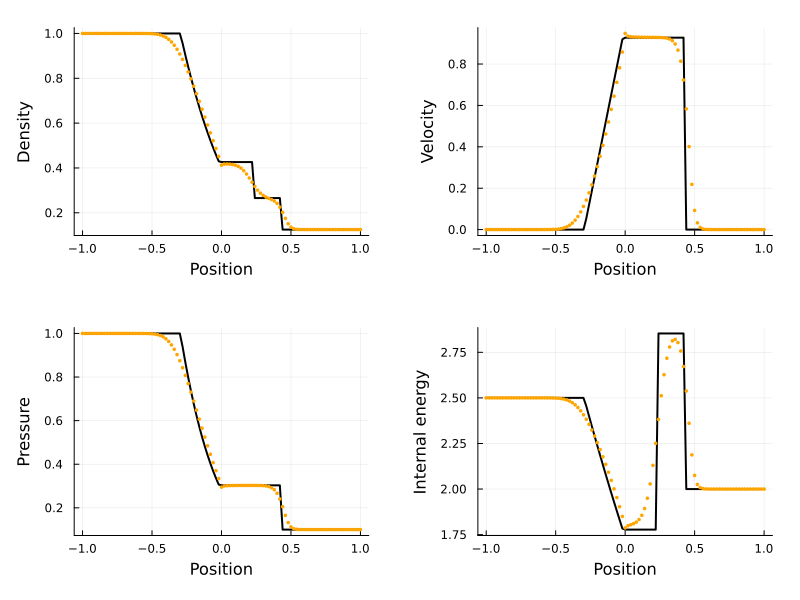

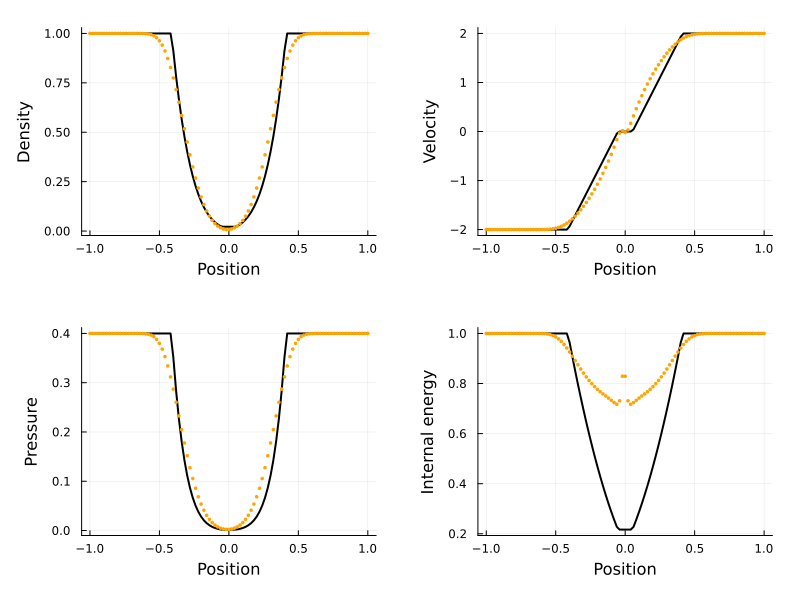

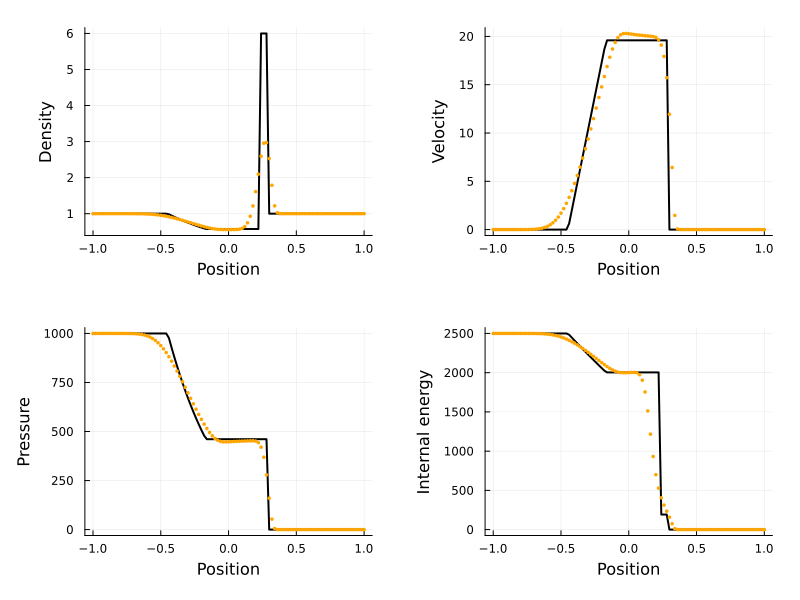

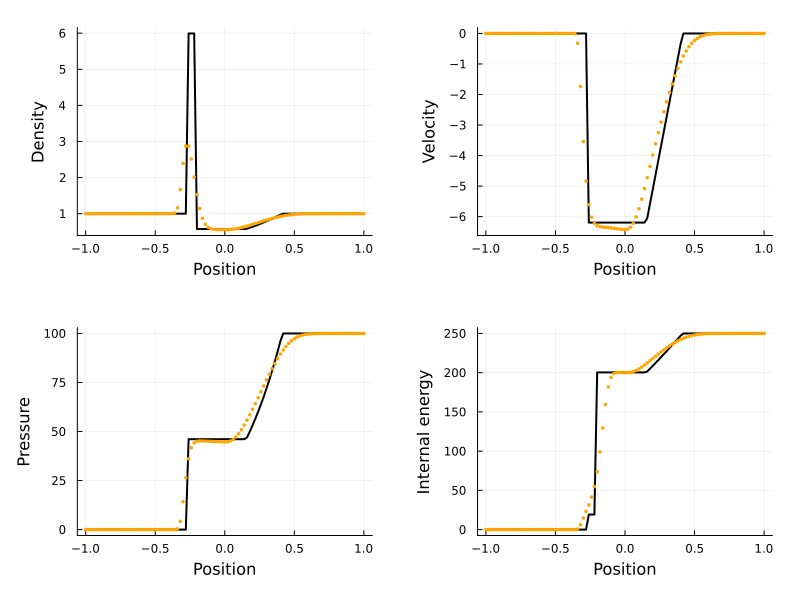

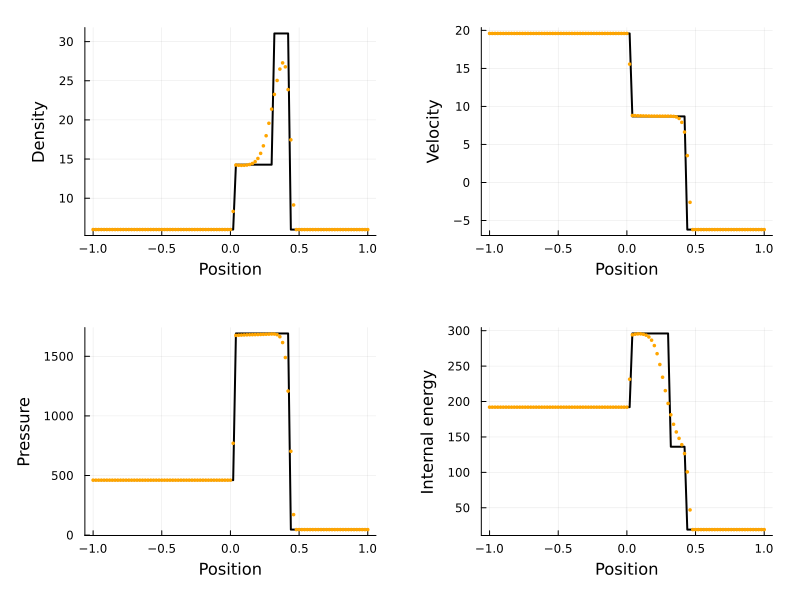

In [4]:
xs = collect(BigFloat("-1"):BigFloat("0.02"):BigFloat("1"))
for i in 1:5
    display(exact_plots(i, xs))
end

In [5]:
using Statistics
using Polynomials

function loghloge(TestCase::Int64)

    default(:xlabel, "h")
    default(:legend, :bottomright)
    default(:xscale, :log10)
    default(:yscale, :log10)

    Wₗ = PrimVars(Tuple(Tests[TestCase, 2:4]))
    Wᵣ = PrimVars(Tuple(Tests[TestCase, 5:7]))
    t_max = Tests[TestCase, 8]
    max_h = BigFloat("0.04")
    min_h = BigFloat("0.0025")

    es = DataFrame(
        hs = BigFloat[],
        ρs_error = BigFloat[],
        us_error = BigFloat[],
        ps_error = BigFloat[],
        Es_error = BigFloat[]
    )
    for h in logrange(max_h, min_h, 5)

        function BCₗ(t::BigFloat)
            return Wₗ
        end

        function BCᵣ(t::BigFloat)
            return Wᵣ
        end

        function IC(x::BigFloat)
            return x ≥ 0 ? Wᵣ : Wₗ
        end

        xs = collect(BigFloat("-1.0"):h:BigFloat("1.0"))

        ρs = zeros(length(xs))
        us = zeros(length(xs))
        ps = zeros(length(xs))
        Es = zeros(length(xs))

        W = W⁺(Wₗ, Wᵣ, γ, ε)
        a_max = 0
        for x in xs
            W_f = IC(x)
            a = sound_speed(W_f, γ)
            a_max = max(a, a_max)
        end
        Δt = find_Δt(BigFloat("0.125"), h, a_max, t_max)
        Ws = IC.(xs)
        pushfirst!(Ws, BCₗ(BigFloat(0)))
        push!(Ws, BCᵣ(BigFloat(0)))
        for t in BigFloat("0"):Δt:t_max
            Ws = GodunovMethodOneStep(Ws, xs, h, Δt, γ, ε)
            for x in eachindex(xs)
                W_exact = W(xs[x] / t)
                ρs[x] += abs(Ws[x].ρ - W_exact.ρ)
                us[x] += abs(Ws[x].u - W_exact.u)
                ps[x] += abs(Ws[x].p - W_exact.p)
                Es[x] += abs(Ws[x].p / (γ - 1) / Ws[x].ρ - W_exact.p / (γ - 1) / W_exact.ρ)
            end                
            pushfirst!(Ws, BCₗ(t))
            push!(Ws, BCᵣ(t))
        end
        pop!(Ws)
        popfirst!(Ws)

        push!(es, [h sum(ρs)*h*Δt sum(us)*h*Δt sum(ps)*h*Δt sum(Es)*h*Δt])
    end

    pretty_table(es;
        formatters = [fmt__printf("%.4f", [1]), fmt__printf("%.2e", [2, 3, 4, 5])],
        style = TextTableStyle(; table_border = crayon"yellow"),
        fit_table_in_display_horizontally = false,
    )

    p1 = fit(log10.(es[!, :hs]), log10.(es[!, :ρs_error]), 1)[1]
    p1_text = string(round(Float64(p1), digits=4))

    p2 = fit(log10.(es[!, :hs]), log10.(es[!, :us_error]), 1)[1]
    p2_text = string(round(Float64(p2), digits=4))

    p3 = fit(log10.(es[!, :hs]), log10.(es[!, :ps_error]), 1)[1]
    p3_text = string(round(Float64(p3), digits=4))

    p4 = fit(log10.(es[!, :hs]), log10.(es[!, :Es_error]), 1)[1]
    p4_text = string(round(Float64(p4), digits=4))

    plot(
        plot(es[!, :hs], es[!, :ρs_error], ylabel="Density error", label="p = "*p1_text),
        plot(es[!, :hs], es[!, :us_error], ylabel="Velocity error", label="p = "*p2_text),
        plot(es[!, :hs], es[!, :ps_error], ylabel="Pressure error", label="p = "*p3_text),
        plot(es[!, :hs], es[!, :Es_error], ylabel="Internal energy error", label="p = "*p4_text),
        layout=(2,2),
        margin=5Plots.mm,
        size=(800,600)
    )

end

loghloge (generic function with 1 method)

┌──────────┬──────────┬──────────┬──────────┬──────────┐
│       hs │ ρs_error │ us_error │ ps_error │ Es_error │
│ BigFloat │ BigFloat │ BigFloat │ BigFloat │ BigFloat │
├──────────┼──────────┼──────────┼──────────┼──────────┤
│   0.0400 │ 7.43e-03 │ 1.65e-02 │ 7.71e-03 │ 2.66e-02 │
│   0.0200 │ 5.15e-03 │ 1.08e-02 │ 5.03e-03 │ 1.88e-02 │
│   0.0100 │ 4.04e-03 │ 8.89e-03 │ 3.88e-03 │ 1.48e-02 │
│   0.0050 │ 2.25e-03 │ 3.88e-03 │ 1.94e-03 │ 8.35e-03 │
│   0.0025 │ 1.45e-03 │ 2.23e-03 │ 1.17e-03 │ 5.50e-03 │
└──────────┴──────────┴──────────┴──────────┴──────────┘


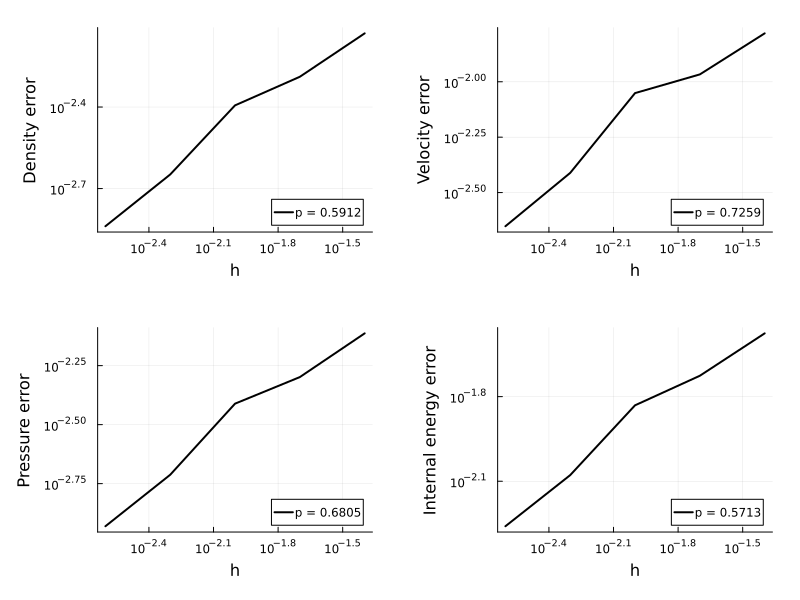

In [6]:
loghloge(1)

┌──────────┬──────────┬──────────┬──────────┬──────────┐
│       hs │ ρs_error │ us_error │ ps_error │ Es_error │
│ BigFloat │ BigFloat │ BigFloat │ BigFloat │ BigFloat │
├──────────┼──────────┼──────────┼──────────┼──────────┤
│   0.0400 │ 1.05e-02 │ 3.49e-02 │ 5.30e-03 │ 2.67e-02 │
│   0.0200 │ 5.89e-03 │ 2.00e-02 │ 3.27e-03 │ 2.12e-02 │
│   0.0100 │ 3.66e-03 │ 1.13e-02 │ 2.16e-03 │ 1.68e-02 │
│   0.0050 │ 2.36e-03 │ 6.26e-03 │ 1.41e-03 │ 1.24e-02 │
│   0.0025 │ 1.56e-03 │ 3.58e-03 │ 9.01e-04 │ 8.62e-03 │
└──────────┴──────────┴──────────┴──────────┴──────────┘


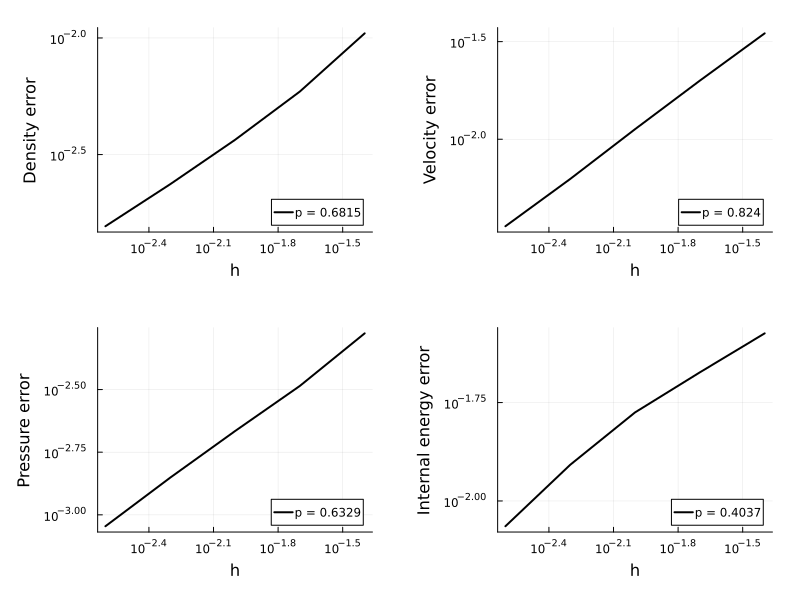

In [7]:
loghloge(2)